# 01 · Exploratory data analysis

Questions this notebook answers before any modelling:

1. What does total demand look like over time: trend, seasonality, the Christmas peak?
2. How concentrated is demand across products: is a top-500 cut reasonable?
3. How much do the one-off bulk orders matter?
4. What kind of demand are we forecasting: smooth, erratic, intermittent or lumpy?
5. What do individual product series look like?

Inputs: `data/processed/sales.parquet` (clean lines) and `data/processed/weekly.parquet` (selected products × weeks).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

from forecasting.data.weekly import (
    WeeklyConfig, complete_weeks, first_test_week, flag_bulk, trading_days, week_start,
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

sales = pd.read_parquet(ROOT / "data/processed/sales.parquet")
weekly = pd.read_parquet(ROOT / "data/processed/weekly.parquet")
cfg = WeeklyConfig()

# One look for every chart: thin marks, recessive grid, text in neutral ink
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID, "axes.labelcolor": INK_2,
    "axes.titlelocation": "left", "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "lines.linewidth": 2, "legend.frameon": False,
})
thousands = mticker.FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k")

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")


## 1 · Total weekly demand

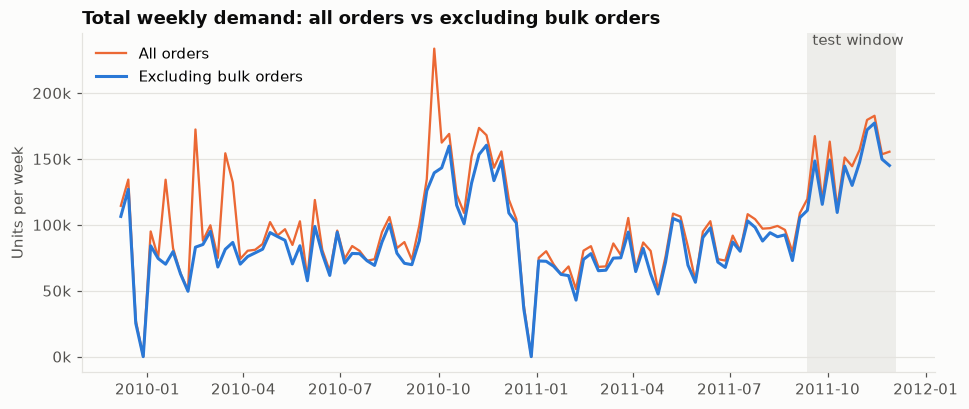

Weeks: 2009-12-07 to 2011-11-28 (104 weeks), test from 2011-09-12
Weeks with no sales at all: ['2009-12-28', '2010-12-27']


In [2]:
first, last = complete_weeks(sales["invoice_date"])
cutoff = first_test_week(last, cfg)
bulk = flag_bulk(sales, cfg, before=cutoff)
all_weeks = pd.date_range(first, last, freq="W-MON")
s = sales.assign(week=week_start(sales["invoice_date"]), bulk=bulk)
s = s[(s["week"] >= first) & (s["week"] <= last)]

# reindex to every week: a week with no sales must show as 0, not be skipped by the line
total = s.groupby("week")["quantity"].sum().reindex(all_weeks, fill_value=0)
base = s[~s["bulk"]].groupby("week")["quantity"].sum().reindex(all_weeks, fill_value=0)

fig, ax = plt.subplots()
ax.plot(total.index, total, color=ORANGE, linewidth=1.5, label="All orders")
ax.plot(base.index, base, color=BLUE, label="Excluding bulk orders")
ax.yaxis.set_major_formatter(thousands)
ax.set_ylabel("Units per week")
ax.set_title("Total weekly demand: all orders vs excluding bulk orders")
ax.axvspan(cutoff, last + pd.Timedelta(days=6), color=GRID, alpha=0.6, linewidth=0)
ax.text(cutoff, ax.get_ylim()[1], " test window", va="top", color=INK_2)
ax.legend(loc="upper left")
save(fig, "01_total_weekly")
plt.show()

print(f"Weeks: {first.date()} to {last.date()} ({len(all_weeks)} weeks), test from {cutoff.date()}")
print("Weeks with no sales at all:", [str(w.date()) for w in total[total == 0].index])


### Calendar: closures and trading days

Dips that are not about demand: the shop closes around Christmas and on bank holidays. A closed day is known in advance, so trading days per week can be a feature for the future too, not only an explanation of the past.

In [3]:
days = trading_days(sales).reindex(all_weeks, fill_value=0)
print("Weeks by number of trading days:")
print(days.value_counts().sort_index().to_string())

weekday = sales["invoice_date"].dt.day_name().value_counts()
print("\nLines by weekday:")
print(weekday.reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]).fillna(0).astype(int).to_string())

short = days[days < days.mode().iloc[0]]
print("\nWeeks with fewer trading days than usual:")
print(pd.DataFrame({"trading_days": short, "units": total.reindex(short.index)}).to_string())


Weeks by number of trading days:
trading_days
0     2
3     1
4     4
5     8
6    89

Lines by weekday:
invoice_date
Monday       177427
Tuesday      184240
Wednesday    171202
Thursday     188038
Friday       144021
Saturday        385
Sunday       130723

Weeks with fewer trading days than usual:
            trading_days  units
2009-12-21             3  27628
2009-12-28             0      0
2010-03-29             4  74119
2010-04-05             5  80336
2010-05-03             5  91889
2010-05-31             5  59340
2010-08-30             5  86896
2010-12-20             4  39192
2010-12-27             0      0
2011-01-03             5  74974
2011-04-18             4  80208
2011-04-25             4  50457
2011-05-02             5  76101
2011-05-30             5  57578
2011-08-29             5  79507


Same weeks, one line per year: does the seasonal shape repeat? With only two years we see the yearly cycle twice. Any seasonality the model learns rests on that, which is a limitation worth stating.

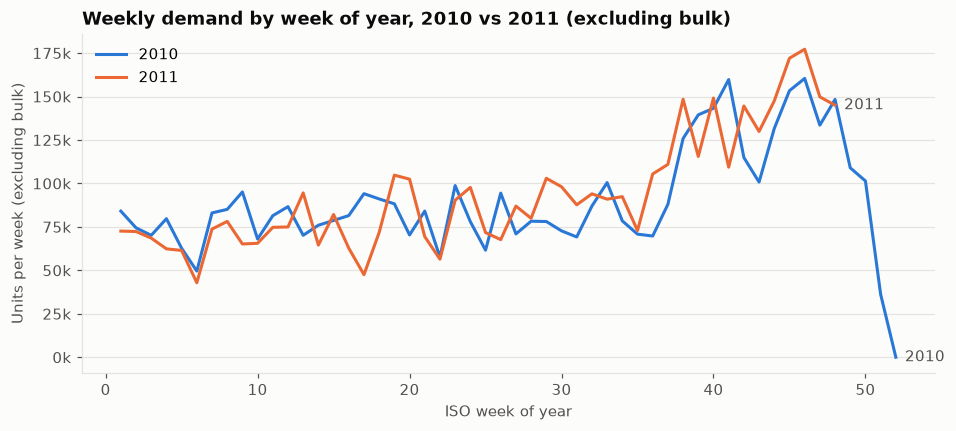

In [4]:
yoy = base.to_frame("units").assign(
    year=lambda d: d.index.isocalendar().year.values,
    week_no=lambda d: d.index.isocalendar().week.values,
)
fig, ax = plt.subplots()
for year, color in [(2010, BLUE), (2011, ORANGE)]:
    part = yoy[yoy["year"] == year]
    ax.plot(part["week_no"], part["units"], color=color, label=str(year))
    ax.annotate(str(year), (part["week_no"].iloc[-1], part["units"].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", color=INK_2, va="center")
ax.yaxis.set_major_formatter(thousands)
ax.set_xlabel("ISO week of year")
ax.set_ylabel("Units per week (excluding bulk)")
ax.set_title("Weekly demand by week of year, 2010 vs 2011 (excluding bulk)")
ax.legend(loc="upper left")
save(fig, "02_year_over_year")
plt.show()


## 2 · How concentrated is demand?

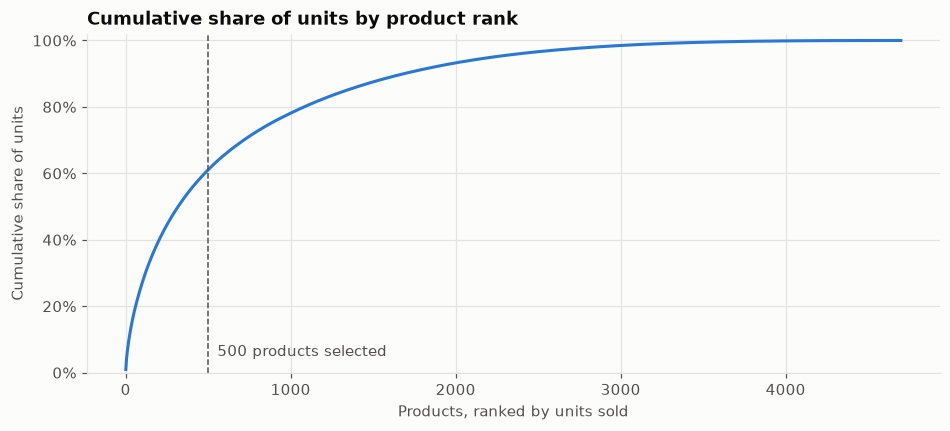

Top   100 products: 27.0% of units
Top   500 products: 61.1% of units
Top  1000 products: 78.1% of units
All products: 4,698


In [5]:
by_item = sales[~bulk].groupby("stock_code")["quantity"].sum().sort_values(ascending=False)
cum_share = by_item.cumsum() / by_item.sum()
n_sel = weekly["stock_code"].nunique()

fig, ax = plt.subplots()
ax.plot(np.arange(1, len(cum_share) + 1), cum_share, color=BLUE)
ax.axvline(n_sel, color=INK_2, linewidth=1, linestyle="--")
ax.annotate(f"{n_sel} products selected", (n_sel, 0.05), xytext=(6, 0), textcoords="offset points", color=INK_2)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_ylim(0, 1.02)
ax.set_xlabel("Products, ranked by units sold")
ax.set_ylabel("Cumulative share of units")
ax.set_title("Cumulative share of units by product rank")
ax.grid(axis="x", color=GRID)
save(fig, "03_concentration")
plt.show()

for n in (100, 500, 1000):
    print(f"Top {n:>5} products: {cum_share.iloc[min(n, len(cum_share)) - 1]:.1%} of units")
print(f"All products: {len(by_item):,}")


## 3 · Bulk orders

In [6]:
bulk_lines = sales[bulk].sort_values("quantity", ascending=False)
print(f"Bulk lines: {len(bulk_lines):,} "
      f"({bulk_lines['quantity'].sum() / sales['quantity'].sum():.2%} of units, "
      f"{bulk_lines['customer_id'].nunique()} customers, {bulk_lines['stock_code'].nunique()} products)")
print(f"Rule: quantity > {cfg.bulk_factor:g} x the product's median line and >= {cfg.bulk_min_quantity} units")
bulk_lines[["invoice", "invoice_date", "stock_code", "description", "quantity", "price", "customer_id", "country"]].head(20)


Bulk lines: 833 (9.71% of units, 126 customers, 396 products)
Rule: quantity > 20 x the product's median line and >= 500 units


,invoice,invoice_date,stock_code,description,quantity,price,customer_id,country
85960,497946,2010-02-15 11:57:00,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,13902,Denmark
120207,501534,2010-03-17 13:09:00,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,13902,Denmark
120209,501534,2010-03-17 13:09:00,21091,SET/6 WOODLAND PAPER PLATES,12960,0.10,13902,Denmark
120210,501534,2010-03-17 13:09:00,21085,SET/6 WOODLAND PAPER CUPS,12744,0.10,13902,Denmark
120208,501534,2010-03-17 13:09:00,21092,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,13902,Denmark
127616,502269,2010-03-23 15:36:00,21982,PACK OF 12 SUKI TISSUES,10000,0.25,17940,United Kingdom
127615,502269,2010-03-23 15:36:00,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,0.25,17940,United Kingdom
127617,502269,2010-03-23 15:36:00,21980,PACK OF 12 RED SPOTTY TISSUES,10000,0.25,17940,United Kingdom
127618,502269,2010-03-23 15:36:00,21981,PACK OF 12 WOODLAND TISSUES,10000,0.25,17940,United Kingdom
88649,498152,2010-02-17 10:51:00,85220,SMALL FAIRY CAKE FRIDGE MAGNETS,9456,0.30,13902,Denmark


How sensitive is the share of bulk to the rule? And how much of it repeats: the same customer buying the same product in bulk more than once is closer to regular demand than to a one-off.

In [7]:
rows = []
for factor in (10, 20, 50, 100):
    for floor in (200, 500, 1000):
        flags = flag_bulk(sales, WeeklyConfig(bulk_factor=factor, bulk_min_quantity=floor), before=cutoff)
        b = sales[flags]
        pair_count = b.groupby(["customer_id", "stock_code"])["quantity"].transform("size")
        rows.append({
            "factor": factor, "min units": floor, "lines": len(b),
            "share of units": b["quantity"].sum() / sales["quantity"].sum(),
            "customers": b["customer_id"].nunique(),
            "repeat share": b.loc[pair_count > 1, "quantity"].sum() / max(b["quantity"].sum(), 1),
            "top customer share": b.groupby("customer_id")["quantity"].sum().max() / max(b["quantity"].sum(), 1),
        })
pd.DataFrame(rows).style.format({"share of units": "{:.1%}", "repeat share": "{:.0%}", "top customer share": "{:.0%}"})


,factor,min units,lines,share of units,customers,repeat share,top customer share
0,10,200,4207,19.1%,386,59%,11%
1,10,500,922,10.3%,130,50%,19%
2,10,1000,279,6.4%,57,43%,30%
3,20,200,3371,16.7%,324,56%,12%
4,20,500,833,9.7%,126,48%,21%
5,20,1000,270,6.3%,55,42%,31%
6,50,200,1913,11.9%,173,49%,17%
7,50,500,608,8.1%,88,42%,24%
8,50,1000,224,5.8%,45,39%,34%
9,100,200,858,7.9%,102,38%,24%


## 4 · What kind of demand is this?

The Syntetos–Boylan classification places each product by two numbers:

- **ADI**: average weeks between non-zero weeks. Above 1.32 means demand is *intermittent*.
- **CV²**: squared coefficient of variation of the non-zero quantities. Above 0.49 means sizes are *erratic*.

Smooth demand suits most methods. Intermittent and lumpy demand is where naive forecasts are hard to beat, and where MAPE breaks because of the zeros.

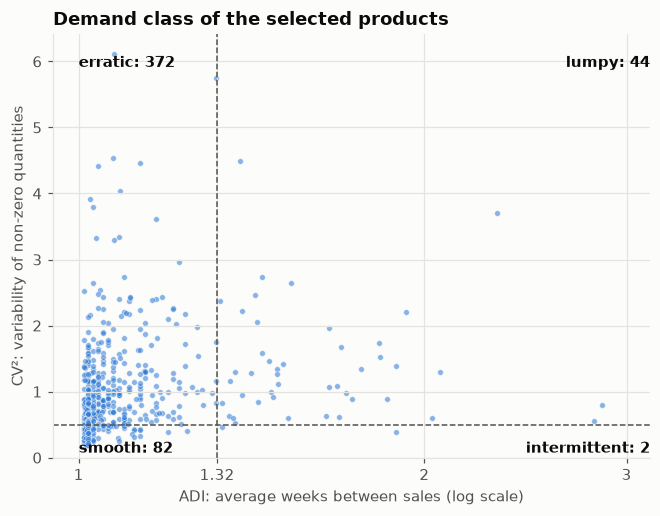

class
erratic         372
smooth           82
lumpy            44
intermittent      2

Share of zero weeks among selected products: 8.6%


In [10]:
def classify(g):
    q = g["quantity"] - g["bulk_quantity"]
    nz = q[q > 0]
    adi = len(q) / max(len(nz), 1)
    cv2 = (nz.std(ddof=0) / nz.mean()) ** 2 if len(nz) > 1 else 0.0
    return pd.Series({"adi": adi, "cv2": cv2, "zero_share": (q == 0).mean()})

profile = weekly.groupby("stock_code").apply(classify)
profile["class"] = np.select(
    [(profile.adi <= 1.32) & (profile.cv2 <= 0.49), (profile.adi <= 1.32), (profile.cv2 <= 0.49)],
    ["smooth", "erratic", "intermittent"], default="lumpy",
)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(profile["adi"], profile["cv2"], s=14, color=BLUE, alpha=0.55, edgecolor="#fcfcfb", linewidth=0.5)
ax.axvline(1.32, color=INK_2, linewidth=1, linestyle="--")
ax.axhline(0.49, color=INK_2, linewidth=1, linestyle="--")
ax.set_xscale("log")
ax.xaxis.set_major_locator(mticker.FixedLocator([1, 1.32, 2, 3, 5, 10, 20]))
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.xaxis.set_minor_locator(mticker.NullLocator())
counts = profile["class"].value_counts()
xmax, ymax = profile["adi"].max() * 1.1, max(profile["cv2"].max() * 1.05, 1)
ax.set_xlim(0.95, max(xmax, 3)); ax.set_ylim(0, ymax)
for label, x, y, ha in [("smooth", 1.0, 0.02, "left"), ("erratic", 1.0, ymax * 0.95, "left"),
                         ("intermittent", ax.get_xlim()[1], 0.02, "right"), ("lumpy", ax.get_xlim()[1], ymax * 0.95, "right")]:
    ax.text(x, y, f"{label}: {counts.get(label, 0)}", ha=ha, va="bottom" if y < 0.1 else "top", color=INK, fontweight="bold")
ax.set_xlabel("ADI: average weeks between sales (log scale)")
ax.set_ylabel("CV²: variability of non-zero quantities")
ax.set_title("Demand class of the selected products")
ax.grid(axis="x", color=GRID)
save(fig, "04_demand_classes")
plt.show()

print(counts.to_string())
print(f"\nShare of zero weeks among selected products: {(weekly['quantity'] == 0).mean():.1%}")


## 5 · Example products

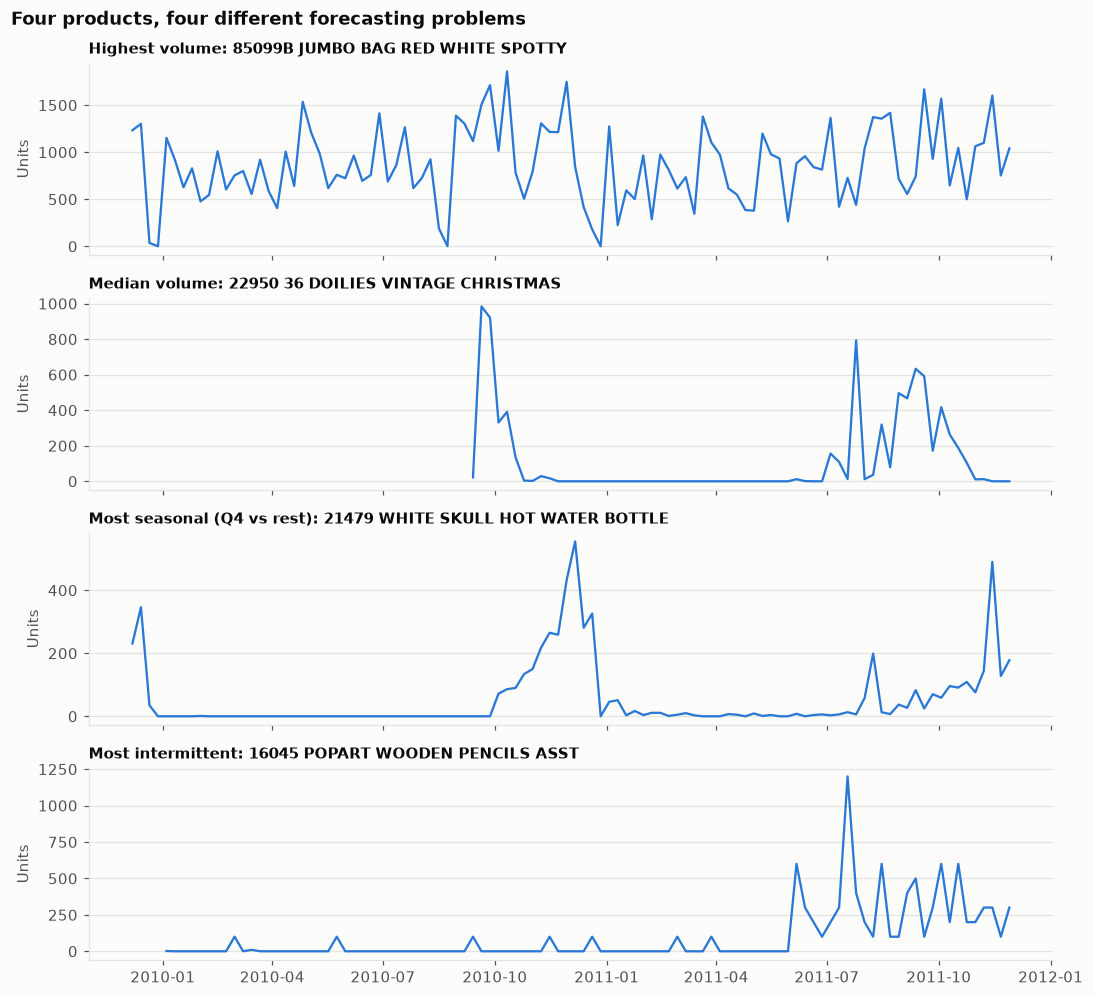

In [11]:
q4 = weekly.assign(base=weekly["quantity"] - weekly["bulk_quantity"], q4=weekly["week"].dt.quarter == 4)
seasonality = q4.groupby(["stock_code", "q4"])["base"].mean().unstack().pipe(lambda t: t[True] / t[False].clip(lower=0.1))
volume = q4.groupby("stock_code")["base"].sum()

examples = {
    "Highest volume": volume.idxmax(),
    "Median volume": volume.sort_values().index[len(volume) // 2],
    "Most seasonal (Q4 vs rest)": seasonality.idxmax(),
    "Most intermittent": profile["zero_share"].idxmax(),
}
desc = sales.drop_duplicates("stock_code").set_index("stock_code")["description"]

fig, axes = plt.subplots(len(examples), 1, figsize=(10, 2.3 * len(examples)), sharex=True)
for ax, (why, code) in zip(axes, examples.items()):
    g = q4[q4["stock_code"] == code]
    ax.plot(g["week"], g["base"], color=BLUE, linewidth=1.5)
    ax.set_title(f"{why}: {code} {desc.get(code, '')}", fontsize=10)
    ax.set_ylabel("Units")
fig.suptitle("Four products, four different forecasting problems", x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "05_example_products")
plt.show()


## Findings

- **Weeks:** 104 full weeks, 2009-12-07 to 2011-11-28; test window = last 12 weeks from 2011-09-12.
- **Seasonality:** peak September to November, same shape both years; each product has its own season.
- **Calendar:** 6 trading days is normal (Sun–Fri); the 15 short weeks are all UK holidays → `trading_days` feature.
- **Concentration:** top 500 = 61% of units; the 500 selected (history + still selling) cover 57%.
- **Bulk orders:** 833 lines, 9.7% of units, ~half repeating. Target = demand excluding bulk; total demand reported as a secondary check.
- **Demand classes:** 372 erratic, 82 smooth, 44 lumpy, 2 intermittent; 8.6% zero weeks → WAPE + MASE, no MAPE; seasonal naive as a baseline.